## 1. Setup

### 1.1 Load, scope and split

The same steps as `01_scoping_eda.ipynb` (sections 2 and 3.1), without the checks and explanations. The seed and the
row order are the same, so train, validation and test contain the same patients the EDA decisions were based on.


In [19]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline




DATA_DIR = Path("../data/raw")  # notebook runs from notebooks/
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]

# Discharged as expired (11, 19, 20, 21) or to hospice (13, 14)
EXCLUDED_DISCHARGE = [11, 13, 14, 19, 20, 21]


def icd9_group(code: str | float) -> str:
    """Map an ICD-9 code to one of the 9 disease groups of Strack et al. (2014)."""
    if pd.isna(code):
        return "Missing"
    if code[0] in "VE":  # supplementary (V) and external-cause (E) codes
        return "Other"
    value = float(code)
    chapter = int(value)  # integer part: "786.05" -> 786
    if 390 <= value < 460 or chapter == 785:
        return "Circulatory"
    if 460 <= value < 520 or chapter == 786:
        return "Respiratory"
    if 520 <= value < 580 or chapter == 787:
        return "Digestive"
    if chapter == 250:
        return "Diabetes"
    if 800 <= value < 1000:
        return "Injury"
    if 710 <= value < 740:
        return "Musculoskeletal"
    if 580 <= value < 630 or chapter == 788:
        return "Genitourinary"
    if 140 <= value < 240:
        return "Neoplasms"
    return "Other"


df_raw = pd.read_csv(
    DATA_DIR / "diabetic_data.csv",
    na_values=["?"],        # the dataset's only missing-value token
    keep_default_na=False,  # keep "None" (test not measured) as a category
    low_memory=False,
)

# Scoping: first encounter per patient, no death / hospice, known gender
df = df_raw.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
df = df[~df["discharge_disposition_id"].isin(EXCLUDED_DISCHARGE)]
df = df[df["gender"] != "Unknown/Invalid"].reset_index(drop=True)

# 1 = readmitted within 30 days; ">30" and "NO" both become 0
df["target"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns="readmitted")

# Empty code beyond number_diagnoses = no such diagnosis -> "Absent" instead of "Missing"
for position, col in enumerate(DIAG_COLS, start=1):
    groups = df[col].map(icd9_group)
    absent = df[col].isna() & (df["number_diagnoses"] < position)
    df[f"{col}_group"] = groups.mask(absent, "Absent")

# Same seed and order as the EDA, so the three parts contain the same patients
df_full_train, df_test = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, stratify=df_full_train["target"], random_state=1
)

for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{name}: {len(part)} rows, positive rate {part['target'].mean():.2%}")


train: 41982 rows, positive rate 8.97%
val: 13994 rows, positive rate 8.98%
test: 13994 rows, positive rate 8.97%


## 2. Data preparation

### 2.1 Fixed cleaning rules

The decisions from section 3.6 of the EDA. A function, so that train, validation and later the service all get exactly the same
treatment. These rules are fixed in advance and read nothing from the data, so they cannot leak information from validation.


In [2]:
DROP_COLS = [
    "encounter_id", "patient_nbr",  # identifiers
    "examide", "citoglipton", "glimepiride-pioglitazone", "metformin-pioglitazone",  # one value in train
    "weight", "payer_code",  # mostly missing
    *DIAG_COLS,  # replaced by the _group columns
]

# Codes that mean "not available / NULL / not mapped" in IDS_mapping.csv
UNKNOWN_CODES = {
    "admission_type_id": [5, 6, 8],
    "discharge_disposition_id": [18, 25, 26],
    "admission_source_id": [9, 15, 17, 20, 21],
}


def clean(data: pd.DataFrame) -> pd.DataFrame:
    """Apply the fixed rules of the 3.6 decisions table. Nothing here is learned from the data."""
    data = data.drop(columns=DROP_COLS)
    data[["race", "medical_specialty"]] = data[["race", "medical_specialty"]].fillna("Missing")
    for col, codes in UNKNOWN_CODES.items():
        # Codes become text, so a model cannot treat them as quantities
        data[col] = data[col].astype(str).mask(data[col].isin(codes), "Unknown")
    return data


# New names, so df_train and df_val stay intact and this cell can be re-run
train_clean = clean(df_train)
val_clean = clean(df_val)

print(train_clean.shape, val_clean.shape)
print("missing values left:", train_clean.isna().sum().sum(), val_clean.isna().sum().sum())
train_clean[list(UNKNOWN_CODES)].eq("Unknown").sum()


(41982, 42) (13994, 42)
missing values left: 0 0


admission_type_id           4716
discharge_disposition_id    1960
admission_source_id         3035
dtype: int64

### 2.2 Merge rare categories

Categories with under 100 training patients become "Other", in `medical_specialty` and the three ID columns, because rates
measured on tiny groups are unreliable. Unlike 2.1, this step learns from the data: the lists of kept categories come from
the training set only, and the same lists are applied to validation and later saved for the service.


In [3]:
MIN_PATIENTS = 100
RARE_COLS = ["medical_specialty", *UNKNOWN_CODES]  # unpacking a dict gives its keys


def fit_kept_categories(train: pd.DataFrame) -> dict[str, list[str]]:
    """Return, per column, the categories with at least MIN_PATIENTS patients in the training data."""
    kept = {}
    for col in RARE_COLS:
        counts = train[col].value_counts()
        kept[col] = counts[counts >= MIN_PATIENTS].index.tolist()
    return kept


def merge_rare(data: pd.DataFrame, kept: dict[str, list[str]]) -> pd.DataFrame:
    """Replace every category outside the kept lists with "Other"."""
    data = data.copy()  # leave the caller's DataFrame untouched
    for col, categories in kept.items():
        # .where keeps the value when the condition is true, otherwise writes "Other"
        data[col] = data[col].where(data[col].isin(categories), "Other")
    return data


kept_categories = fit_kept_categories(train_clean)
train_prep = merge_rare(train_clean, kept_categories)
val_prep = merge_rare(val_clean, kept_categories)

pd.DataFrame({
    "before": train_clean[RARE_COLS].nunique(),
    "after": train_prep[RARE_COLS].nunique(),
    "train_to_other": train_prep[RARE_COLS].eq("Other").sum(),
    "val_to_other": val_prep[RARE_COLS].eq("Other").sum(),
})


,before,after,train_to_other,val_to_other
medical_specialty,66,22,916,320
admission_type_id,6,5,14,4
discharge_disposition_id,20,11,151,52
admission_source_id,15,8,100,35


### 2.3 Feature sets and target

Two lists of inputs go to modelling: all columns, and a reduced list without the 11 near-constant drugs and `gender`.

**Decision rule, fixed before any model is trained:** whenever two options are compared (more or fewer columns, a
transformation, a larger model, an ensemble), the more complex one is kept only if it adds more than 0.005 validation
AUC; otherwise the simpler one wins. Small differences can come from chance alone: the random seed, or which patients
ended up in validation. This is a fixed-number version of the one-standard-error rule (keep the simplest model whose
score is within the noise of the best). Whether 0.005 matches the real noise of this data is measured in 4.2, once the
models exist.

Applied here: the reduced list goes into the service unless it lowers the validation AUC by more than 0.005.



In [4]:
# 99%+ of train patients on one value, plus gender (MI 0): removed in the reduced list
LOW_SIGNAL_COLS = [
    "acetohexamide", "metformin-rosiglitazone", "troglitazone", "glipizide-metformin",
    "miglitol", "tolbutamide", "tolazamide", "chlorpropamide", "acarbose", "nateglinide",
    "glyburide-metformin", "gender",
]

FEATURES_ALL = [c for c in train_prep.columns if c != "target"]
FEATURES_REDUCED = [c for c in FEATURES_ALL if c not in LOW_SIGNAL_COLS]

# The 6 skewed counts: log1p is tested against plain values on the logistic regression only
LOG_COLS = [
    "time_in_hospital", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient",
]

y_train = train_prep["target"].to_numpy()
y_val = val_prep["target"].to_numpy()

# Catches a typo in a column name, which the list comprehension above would silently ignore
assert set(LOW_SIGNAL_COLS) <= set(FEATURES_ALL)
assert set(LOG_COLS) <= set(FEATURES_ALL)

print(f"all: {len(FEATURES_ALL)} inputs, reduced: {len(FEATURES_REDUCED)} inputs")
print(f"y_train mean {y_train.mean():.4f}, y_val mean {y_val.mean():.4f}")


all: 41 inputs, reduced: 29 inputs
y_train mean 0.0897, y_val mean 0.0898


## 3. Models

### 3.1 Logistic regression baseline

The simplest model sets the score the others must beat. Its inputs are the plain counts or `log1p` of the 6 skewed counts:
a linear model feels a value of 10 much more strongly than a 1, so compressing long tails can help it. Both use all columns.
The regularisation strength `C` is then tuned on the version that wins.


In [5]:
def to_dicts(data: pd.DataFrame, features: list[str], log_cols: list[str] | None = None) -> list[dict]:
    """Select the features, optionally apply log1p, and return one dict per patient."""
    X = data[features].copy()
    if log_cols:
        X[log_cols] = np.log1p(X[log_cols])
    return X.to_dict(orient="records")


def evaluate_logreg(features: list[str], log_cols: list[str] | None = None, C: float = 1.0) -> dict[str, float]:
    """Fit on train and return the AUC on train and validation."""
    model = make_pipeline(
        DictVectorizer(),  # one-hot encodes the text columns, passes numbers through
        LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=1),
    )
    model.fit(to_dicts(train_prep, features, log_cols), y_train)

    # [:, 1] is the probability of the positive class (readmitted)
    p_train = model.predict_proba(to_dicts(train_prep, features, log_cols))[:, 1]
    p_val = model.predict_proba(to_dicts(val_prep, features, log_cols))[:, 1]
    return {"train_auc": roc_auc_score(y_train, p_train), "val_auc": roc_auc_score(y_val, p_val)}


logreg_results = pd.DataFrame({
    "plain": evaluate_logreg(FEATURES_ALL),
    "log1p": evaluate_logreg(FEATURES_ALL, LOG_COLS),
}).T
logreg_results.round(4)


,train_auc,val_auc
plain,0.6623,0.6510
log1p,0.6622,0.6519


The baseline reaches a validation AUC of 0.651, well above the 0.566 of the best single numeric column (`time_in_hospital`).
The train AUC (0.662) is close, so the model is not overfitting: this is the score the other models have to beat.

`log1p` adds only 0.0009 (0.6519 vs 0.6510). The rule is to keep a transformation only if it adds more than 0.005 validation
AUC, so the plain counts go forward. This also means one less step to reproduce in the service.


#### Regularisation strength

`C` controls how strongly the model's weights are kept small: a small `C` means a strong penalty and a simpler model, a large
`C` a weak penalty. It is tuned on the plain counts before comparing with the tree-based models.


In [6]:
c_results = pd.DataFrame({
    C: evaluate_logreg(FEATURES_ALL, C=C) for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]
}).T
c_results.index.name = "C"
c_results.round(4)


,train_auc,val_auc
C,,
0.001,0.6359,0.6285
0.010,0.6559,0.6488
0.100,0.6609,0.6509
0.500,0.6621,0.6511
1.000,0.6623,0.6510
5.000,0.6625,0.6512
10.000,0.6625,0.6510


A very small `C` underfits (validation AUC 0.629 at `C` = 0.001): the penalty keeps the weights too small to use the data.
From `C` = 0.1 to 10 the validation AUC is flat, between 0.6509 and 0.6512: with about 42,000 training patients and
179 encoded columns the model does not overfit, so weakening the penalty changes almost nothing. `C` stays at the default
1.0, since the best value (`C` = 5) is only 0.0002 higher, far below the 0.005 rule. The tuned baseline is a validation AUC
of 0.651.


### 3.2 Decision tree

A single tree, mainly to see how its depth trades underfitting against overfitting before moving on to the ensembles. The
evaluation function is now generic: any scikit-learn model goes through the same encoding and the same AUC on train and
validation. Plain counts, as decided in 3.1.


In [7]:
def evaluate(estimator: BaseEstimator, features: list[str]) -> dict[str, float]:
    """Fit DictVectorizer + estimator on train and return the AUC on train and validation."""
    model = make_pipeline(DictVectorizer(), estimator)
    model.fit(to_dicts(train_prep, features), y_train)
    p_train = model.predict_proba(to_dicts(train_prep, features))[:, 1]
    p_val = model.predict_proba(to_dicts(val_prep, features))[:, 1]
    return {"train_auc": roc_auc_score(y_train, p_train), "val_auc": roc_auc_score(y_val, p_val)}


# None = no depth limit: the tree keeps splitting until its leaves cannot be split further
depth_results = pd.DataFrame({
    str(depth): evaluate(DecisionTreeClassifier(max_depth=depth, random_state=1), FEATURES_ALL)
    for depth in [1, 2, 3, 4, 5, 6, 7, 8, 10, 15, None]
}).T
depth_results.round(4)


,train_auc,val_auc
1,0.5798,0.5800
2,0.6019,0.5941
3,0.6186,0.6105
4,0.6259,0.6178
5,0.6364,0.6254
6,0.6446,0.6272
7,0.6533,0.6177
8,0.6654,0.6154
10,0.6915,0.5874
15,0.7962,0.5331


Up to depth 6 the tree **underfits**: train and validation AUC are both low and rise together, because each extra level
learns patterns that hold for new patients too. From depth 7 it **overfits**: train AUC keeps rising while validation falls.
With no limit the tree reaches 1.0 on train and 0.52 on validation, almost a coin flip, because it has memorised individual
patients.

The best tree (depth 6, validation AUC 0.627) is still below the logistic regression (0.651). A depth-6 tree has at most
64 leaves, so it can give only 64 different probabilities, and AUC needs a finer ranking of patients than that. A single tree
also changes a lot with small changes in the data. Random forest averages many trees, each built on a different sample of
the data, to reduce that instability; XGBoost builds trees in sequence, each one correcting the errors of the previous ones.
Both produce much finer probabilities, so they are the next candidates.


#### Minimum leaf size

`min_samples_leaf` stops the tree from creating leaves with very few patients, which is another way to limit overfitting.
It is tested together with depth, including the deeper trees: a large minimum leaf may let a deep tree generalise again.


In [8]:
leaf_results = pd.DataFrame({
    (depth, leaf): evaluate(
        DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1), FEATURES_ALL
    )
    for depth in [4, 5, 6, 8, 10]
    for leaf in [1, 20, 50, 100, 200, 500]
}).T
leaf_results.index.names = ["max_depth", "min_samples_leaf"]

# One row per depth, one column per leaf size: validation AUC only
leaf_results["val_auc"].unstack().round(4)


min_samples_leaf,1,20,50,100,200,500
max_depth,,,,,,
4,0.6178,0.6160,0.6160,0.6159,0.6161,0.6202
5,0.6254,0.6238,0.6254,0.6247,0.6222,0.6158
6,0.6272,0.6250,0.6246,0.6232,0.6264,0.6231
8,0.6154,0.6046,0.6146,0.6277,0.6305,0.6255
10,0.5874,0.5841,0.6056,0.6190,0.6272,0.6187


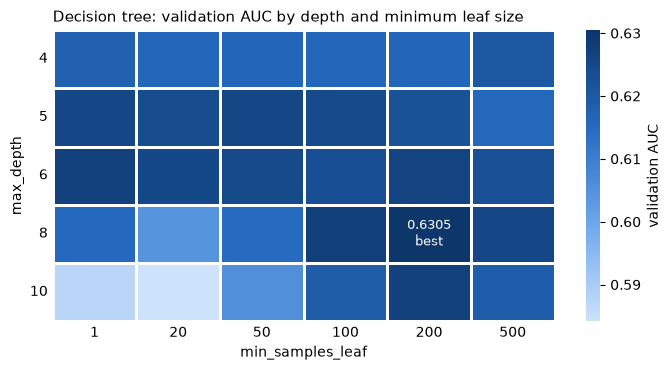

In [9]:
# One blue, light = low AUC, dark = high AUC
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def plot_auc_grid(grid: pd.DataFrame, title: str) -> None:
    """Heatmap of validation AUC over two hyperparameters; only the best cell is labelled."""
    best_row, best_col = grid.stack().idxmax()  # labels of the highest validation AUC
    row, col = grid.index.get_loc(best_row), grid.columns.get_loc(best_col)

    fig, ax = plt.subplots(figsize=(7, 3.8))
    sns.heatmap(grid, cmap=BLUES, linewidths=2, linecolor="white", ax=ax, cbar_kws={"label": "validation AUC"})
    ax.text(col + 0.5, row + 0.5, f"{grid.iloc[row, col]:.4f}\nbest", ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    ax.tick_params(length=0)  # no tick marks, labels only
    ax.yaxis.set_tick_params(rotation=0)
    plt.tight_layout()
    plt.show()


plot_auc_grid(leaf_results["val_auc"].unstack(), "Decision tree: validation AUC by depth and minimum leaf size")


Depths 8 and 10 overfit with small leaves, but recover once each leaf needs 100 to 200 patients: depth 10 goes from 0.587 to
0.627. The best tree (depth 8, `min_samples_leaf` 200) reaches 0.6305, only 0.003 above the best depth-only tree and
0.02 below the logistic regression (0.651). Tuning does not close the gap, so the single tree is not a candidate for the
service; it confirms that the next step is to combine many trees.


### 3.3 Random forest

Many trees, each trained on a random sample of patients and of columns, with their probabilities averaged. Depth and number
of trees are tuned first, then the minimum leaf size around the best depths.


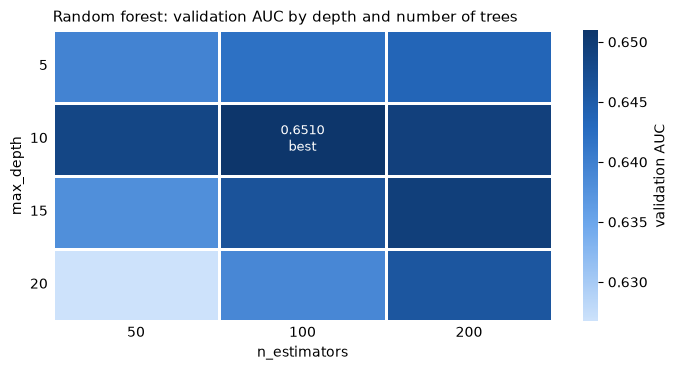

,max_depth,n_estimators,train_auc,val_auc
0,5,50,0.6665,0.6396
1,5,100,0.6698,0.6420
2,5,200,0.6722,0.6436
3,10,50,0.7809,0.6485
4,10,100,0.7927,0.6510
5,10,200,0.7951,0.6493
6,15,50,0.9428,0.6380
7,15,100,0.9525,0.6464
8,15,200,0.9565,0.6495
9,20,50,0.9951,0.6267


In [10]:
rf_depth_results = pd.DataFrame({
    (depth, n): evaluate(
        RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1),  # n_jobs=-1: all CPU cores
        FEATURES_ALL,
    )
    for depth in [5, 10, 15, 20]
    for n in [50, 100, 200]
}).T
rf_depth_results.index.names = ["max_depth", "n_estimators"]

plot_auc_grid(rf_depth_results["val_auc"].unstack(), "Random forest: validation AUC by depth and number of trees")
rf_depth_results.round(4).reset_index()



The forest beats the single tree clearly: 0.651 at depth 10 with 100 trees, against 0.6305 for the best tree, because
averaging many trees gives a much finer ranking of patients. More trees help most when the trees are deep: at depth 20,
going from 50 to 200 trees adds 0.019, since averaging cancels out the noise of each overfitted tree. Differences of about
0.002 (depth 10: 100 vs 200 trees) are random variation, not real improvements.


#### Minimum leaf size

With 200 trees fixed (more trees never hurt accuracy, they only cost time), the minimum leaf size is tested on depths 10,
15 and 20. Depth 5 is left out: it was clearly below the others.


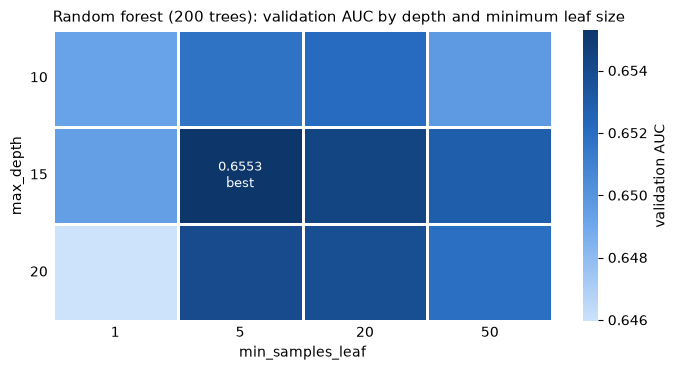

,max_depth,min_samples_leaf,train_auc,val_auc
0,10,1,0.7951,0.6493
1,10,5,0.7521,0.6517
2,10,20,0.7234,0.6521
3,10,50,0.7026,0.6497
4,15,1,0.9565,0.6495
5,15,5,0.8664,0.6553
6,15,20,0.7886,0.6544
7,15,50,0.7396,0.6529
8,20,1,0.9978,0.6460
9,20,5,0.9454,0.6540


In [11]:
rf_leaf_results = pd.DataFrame({
    (depth, leaf): evaluate(
        RandomForestClassifier(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf, random_state=1, n_jobs=-1
        ),
        FEATURES_ALL,
    )
    for depth in [10, 15, 20]
    for leaf in [1, 5, 20, 50]
}).T
rf_leaf_results.index.names = ["max_depth", "min_samples_leaf"]

plot_auc_grid(
    rf_leaf_results["val_auc"].unstack(),
    "Random forest (200 trees): validation AUC by depth and minimum leaf size",
)
rf_leaf_results.round(4).reset_index()


A minimum leaf of 5 to 20 patients helps every depth, most of all the deeper forests: depth 15 goes from 0.6495 to 0.6553
with leaves of at least 5. The best forest (depth 15, `min_samples_leaf` 5, 200 trees) reaches a validation AUC of 0.6553.
That is 0.0043 above the logistic regression (0.651), less than the 0.005 margin a more complex model should add to earn
its place. The final choice is made in section 4, after XGBoost.


### 3.4 XGBoost

Trees built one after another, each one correcting the errors of the trees before it. The learning rate sets how much each
new tree is allowed to correct. XGBoost scores the validation set after every round, so a single fit per learning rate shows
the whole curve: where validation AUC peaks and where more rounds start to overfit.


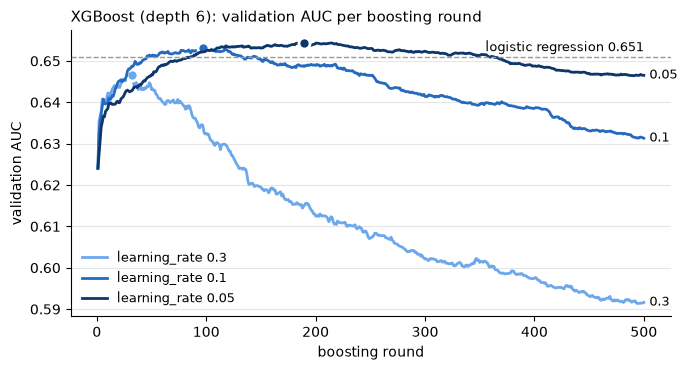

,best_round,best_val_auc
0.30,32,0.6467
0.10,97,0.6530
0.05,189,0.6543


In [13]:
# Encoded once outside the pipeline: eval_set needs the validation matrix already encoded
dv = DictVectorizer()
X_train = dv.fit_transform(to_dicts(train_prep, FEATURES_ALL))
X_val = dv.transform(to_dicts(val_prep, FEATURES_ALL))

val_curves = {}
for eta in [0.3, 0.1, 0.05]:
    model = XGBClassifier(
        n_estimators=500, learning_rate=eta, max_depth=6, eval_metric="auc", random_state=1, n_jobs=-1
    )
    model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)  # AUC on val after every round
    val_curves[eta] = model.evals_result()["validation_0"]["auc"]

val_curves = pd.DataFrame(val_curves, index=pd.RangeIndex(1, 501, name="round"))

# One blue per learning rate, darker = smaller; the dot marks each curve's peak
ETA_COLOURS = {0.3: "#6da7ec", 0.1: "#256abf", 0.05: "#0d366b"}
fig, ax = plt.subplots(figsize=(7, 3.8))
for eta, colour in ETA_COLOURS.items():
    curve = val_curves[eta]
    ax.plot(curve.index, curve, color=colour, linewidth=2, label=f"learning_rate {eta}")
    ax.plot(curve.idxmax(), curve.max(), "o", color=colour, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.annotate(f"{eta}", (curve.index[-1], curve.iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.axhline(0.651, color="#999999", linewidth=1, linestyle="--")
ax.annotate("logistic regression 0.651", (500, 0.651), xytext=(0, 4), textcoords="offset points", ha="right", fontsize=9)
ax.set_xlabel("boosting round")
ax.set_ylabel("validation AUC")
ax.set_title("XGBoost (depth 6): validation AUC per boosting round", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
ax.legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()

pd.DataFrame({"best_round": val_curves.idxmax(), "best_val_auc": val_curves.max()}).round(4)


All three curves rise, peak, then fall: later rounds start fitting noise, so the number of rounds is the main overfitting
control in boosting. A smaller learning rate peaks higher and later and falls more slowly: 0.05 reaches 0.6543 at round 189
and stays above the logistic regression from about round 100 to 350. The learning rate is fixed at 0.05.


#### Tree depth and minimum child weight

`max_depth` limits how many questions each tree asks; `min_child_weight` stops a split when one side would hold too few
patients (the boosting version of `min_samples_leaf`). Both are tested at learning rate 0.05 with 300 rounds: more than the
189 found at depth 6, because shallower trees learn less per round and need more of them.


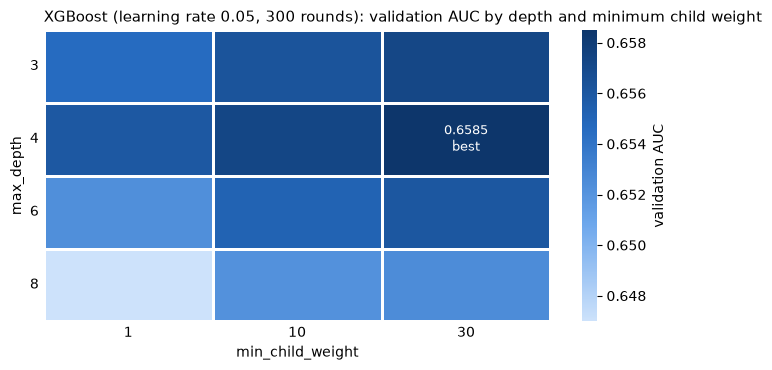

,max_depth,min_child_weight,train_auc,val_auc
0,3,1,0.6942,0.6546
1,3,10,0.6882,0.6563
2,3,30,0.6839,0.6573
3,4,1,0.7257,0.6560
4,4,10,0.7168,0.6573
5,4,30,0.7058,0.6585
6,6,1,0.8111,0.6524
7,6,10,0.7820,0.6552
8,6,30,0.7498,0.6561
9,8,1,0.9049,0.6470


In [14]:
xgb_results = pd.DataFrame({
    (depth, mcw): evaluate(
        XGBClassifier(
            n_estimators=300, learning_rate=0.05, max_depth=depth, min_child_weight=mcw, random_state=1, n_jobs=-1
        ),
        FEATURES_ALL,
    )
    for depth in [3, 4, 6, 8]
    for mcw in [1, 10, 30]
}).T
xgb_results.index.names = ["max_depth", "min_child_weight"]

plot_auc_grid(
    xgb_results["val_auc"].unstack(),
    "XGBoost (learning rate 0.05, 300 rounds): validation AUC by depth and minimum child weight",
)
xgb_results.round(4).reset_index()


Shallow trees work best: depths 3 and 4 beat 6 and 8, because each boosting tree only needs to correct a little of what the
previous trees missed. A larger `min_child_weight` helps at every depth. The best shape is depth 4 with
`min_child_weight` 30: validation AUC 0.6585, 0.0075 above the logistic regression and the first gain larger than the
0.005 margin.


#### Number of rounds for the final shape

The rounds were chosen at depth 6; shallower trees learn less per round, so the curve is measured again for depth 4 and
`min_child_weight` 30, up to 1000 rounds.


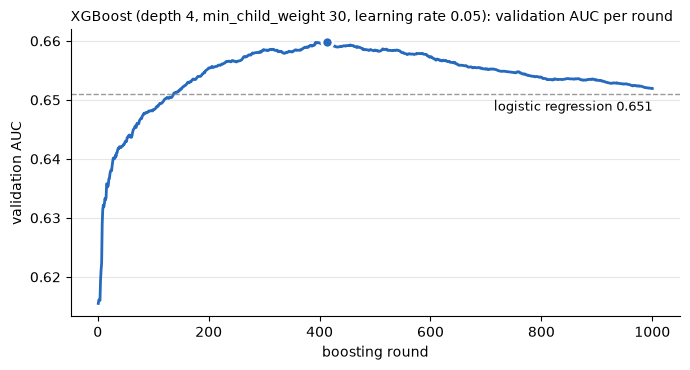

best round: 414, val AUC 0.6598
within 0.002 of the peak: 305 rounds, from round 278 to 587


,train_auc,val_auc
round,,
100,0.6764,0.6484
200,0.6922,0.6554
300,0.7058,0.6585
400,0.7200,0.6597
500,0.7310,0.6585
600,0.7405,0.6573
800,0.7530,0.6539
1000,0.7629,0.6519


In [17]:
model = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4, min_child_weight=30,
    eval_metric="auc", random_state=1, n_jobs=-1,
)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)
rounds_curve = pd.DataFrame({
    "train_auc": model.evals_result()["validation_0"]["auc"],  # first eval_set entry
    "val_auc": model.evals_result()["validation_1"]["auc"],    # second eval_set entry
}, index=pd.RangeIndex(1, 1001, name="round"))

best_round = rounds_curve["val_auc"].idxmax()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(rounds_curve.index, rounds_curve["val_auc"], color="#256abf", linewidth=2)
ax.plot(best_round, rounds_curve["val_auc"].max(), "o", color="#256abf", markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.axhline(0.651, color="#999999", linewidth=1, linestyle="--")
ax.annotate("logistic regression 0.651", (1000, 0.651), xytext=(0, -12), textcoords="offset points", ha="right", fontsize=9)
ax.set_xlabel("boosting round")
ax.set_ylabel("validation AUC")
ax.set_title("XGBoost (depth 4, min_child_weight 30, learning rate 0.05): validation AUC per round", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e6e6", linewidth=0.8)
plt.tight_layout()
plt.show()

best_auc = rounds_curve["val_auc"].max()
# Rounds within 0.002 of the peak (the noise level seen so far): the flat top of the curve
near_best = rounds_curve.index[rounds_curve["val_auc"] >= best_auc - 0.002]
print(f"best round: {best_round}, val AUC {best_auc:.4f}")
print(f"within 0.002 of the peak: {len(near_best)} rounds, from round {near_best.min()} to {near_best.max()}")

rounds_curve.loc[[100, 200, 300, 400, 500, 600, 800, 1000]].round(4)


Validation AUC peaks at round 414 (0.6598), but 305 of the rounds between 278 and 587 stay within 0.002 of that peak, the
size of the random variation seen so far. Choosing the exact peak would fit the noise of this one validation set, so the
number of rounds is set to 400, in the middle of the plateau (validation AUC 0.6597). Final XGBoost settings: learning rate
0.05, depth 4, `min_child_weight` 30, 400 rounds.


## 4. Final choice

### 4.1 The four tuned models side by side

Each model is refitted with its tuned settings and kept, so its validation probabilities can be reused in the next steps.
`vs_logreg` is the gain over the baseline: a more complex model must add more than 0.005 to earn its place.


In [21]:
FINAL_MODELS = {
    "logistic_regression": LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=1),
    "decision_tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=200, random_state=1),
    "random_forest": RandomForestClassifier(
        n_estimators=200, max_depth=15, min_samples_leaf=5, random_state=1, n_jobs=-1
    ),
    "xgboost": XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=4, min_child_weight=30, random_state=1, n_jobs=-1
    ),
}


def fit_model(estimator: BaseEstimator, features: list[str]) -> Pipeline:
    """Fit DictVectorizer + a fresh copy of the estimator on train and return the fitted pipeline."""
    # clone: an unfitted copy, so fitting the same settings twice never overwrites an earlier fitted model
    model = make_pipeline(DictVectorizer(), clone(estimator))
    model.fit(to_dicts(train_prep, features), y_train)
    return model


fitted = {name: fit_model(estimator, FEATURES_ALL) for name, estimator in FINAL_MODELS.items()}
val_probs = {
    name: model.predict_proba(to_dicts(val_prep, FEATURES_ALL))[:, 1] for name, model in fitted.items()
}

comparison = pd.DataFrame({"val_auc": {name: roc_auc_score(y_val, p) for name, p in val_probs.items()}})
comparison["vs_logreg"] = comparison["val_auc"] - comparison.loc["logistic_regression", "val_auc"]
comparison.sort_values("val_auc", ascending=False).round(4)


,val_auc,vs_logreg
xgboost,0.6597,0.0087
random_forest,0.6553,0.0043
logistic_regression,0.6510,0.0000
decision_tree,0.6305,-0.0204


XGBoost is the only model whose gain over the logistic regression (+0.0087) is larger than the 0.005 margin. The random
forest's +0.0043 is below it, and the single tree is clearly worse. XGBoost goes forward to the last two checks: the
reduced feature list and the soft vote.


### 4.2 How large is the noise?

Two checks on the decision rule from 2.3. First, the random seed: the same random forest is refitted with five seeds.
Second, which patients happen to be in validation: the 13,994 validation patients are resampled 1,000 times with
replacement (bootstrap), and the AUC is recomputed each time. The spread of these results shows how large a difference
must be before it can be trusted.


In [23]:
# 1. Random seed: the same random forest settings with five different seeds
seed_aucs = pd.Series({
    seed: roc_auc_score(
        y_val,
        # clone first: set_params on the original would change FINAL_MODELS
        fit_model(clone(FINAL_MODELS["random_forest"]).set_params(random_state=seed), FEATURES_ALL)
        .predict_proba(to_dicts(val_prep, FEATURES_ALL))[:, 1],
    )
    for seed in [1, 2, 3, 4, 5]
}, name="val_auc")
seed_aucs.index.name = "random_state"

# 2. Which patients are in validation: resample them 1,000 times with replacement (bootstrap)
rng = np.random.default_rng(1)
p_xgb, p_logreg = val_probs["xgboost"], val_probs["logistic_regression"]
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_val), len(y_val))  # random patients: some twice, some not at all
    auc_xgb = roc_auc_score(y_val[idx], p_xgb[idx])
    boot.append({"xgboost": auc_xgb, "xgboost_minus_logreg": auc_xgb - roc_auc_score(y_val[idx], p_logreg[idx])})
boot = pd.DataFrame(boot)

print(f"seed:     random forest val AUC from {seed_aucs.min():.4f} to {seed_aucs.max():.4f} (range {seed_aucs.max() - seed_aucs.min():.4f})")
print(f"patients: XGBoost val AUC varies by ±{boot['xgboost'].std():.4f}")
print(f"patients: XGBoost minus logistic regression = {boot['xgboost_minus_logreg'].mean():+.4f} ± {boot['xgboost_minus_logreg'].std():.4f}")
seed_aucs.round(4)


seed:     random forest val AUC from 0.6505 to 0.6553 (range 0.0048)
patients: XGBoost val AUC varies by ±0.0083
patients: XGBoost minus logistic regression = +0.0087 ± 0.0045


random_state
1    0.6553
2    0.6533
3    0.6505
4    0.6542
5    0.6522
Name: val_auc, dtype: float64

The 0.005 margin was set in advance as a judgement. Changing only the random seed moves the random forest by up to 0.0048,
about the size of the margin: differences smaller than that cannot be told apart from chance, so the margin is a
reasonable choice for this data. The random forest's 0.6553 in 4.1 was also the luckiest of the five seeds. The AUC itself
depends on which patients are in validation (±0.0083), but comparing two models on the same patients is more precise:
XGBoost's gain over the logistic regression is +0.0087 ± 0.0045, about twice its own variation, so it is likely real but
modest.


### 4.3 All columns or the reduced list

The reduced list drops the 11 near-constant drugs and `gender` (29 inputs instead of 41). The rule fixed before modelling:
the reduced list goes into the service unless it lowers the validation AUC by more than 0.005.


In [22]:
xgb_reduced = fit_model(FINAL_MODELS["xgboost"], FEATURES_REDUCED)
p_reduced = xgb_reduced.predict_proba(to_dicts(val_prep, FEATURES_REDUCED))[:, 1]

auc_all = comparison.loc["xgboost", "val_auc"]
auc_reduced = roc_auc_score(y_val, p_reduced)
print(f"all columns ({len(FEATURES_ALL)} inputs):     val AUC {auc_all:.4f}")
print(f"reduced list ({len(FEATURES_REDUCED)} inputs): val AUC {auc_reduced:.4f}")
print(f"difference: {auc_reduced - auc_all:+.4f}")


all columns (41 inputs):     val AUC 0.6597
reduced list (29 inputs): val AUC 0.6569
difference: -0.0028


The reduced list costs 0.0028 of validation AUC, less than the 0.005 margin, so it is the feature set of the final model:
29 inputs per patient instead of 41, for practically the same ranking quality.


### 4.4 Soft vote

The three strongest models (logistic regression, random forest, XGBoost) are combined by averaging their predicted
probabilities for each patient. Following the decision rule, the ensemble is kept only if it beats XGBoost alone by more
than 0.005. The comparison uses all columns, where all three models' validation probabilities already exist from 4.1.


In [24]:
vote_members = ["logistic_regression", "random_forest", "xgboost"]
p_vote = np.mean([val_probs[name] for name in vote_members], axis=0)  # average probability per patient

auc_vote = roc_auc_score(y_val, p_vote)
print(f"soft vote ({', '.join(vote_members)}): val AUC {auc_vote:.4f}")
print(f"XGBoost alone: val AUC {auc_all:.4f}")
print(f"difference: {auc_vote - auc_all:+.4f}")


soft vote (logistic_regression, random_forest, xgboost): val AUC 0.6612
XGBoost alone: val AUC 0.6597
difference: +0.0016


The soft vote reaches 0.6612, only 0.0016 above XGBoost alone: below the 0.005 margin and below the seed-to-seed noise
measured in 4.2. It is not kept: one model is simpler to ship and maintain, for practically the same ranking quality.
**Final model: XGBoost (learning rate 0.05, depth 4, `min_child_weight` 30, 400 rounds) on the reduced list of 29 inputs.**
